## ДЗ №2. Матричные факторизации

#### В этой домашке вам предстоит реализовать некоторые базовые модели матричной факторизации

#### Дата выдачи: 17.02.25

#### Мягкий дедлайн: 02.03.25 23:59 MSK

#### Жесткий дедлайн: 09.03.25 23:59 MSK

В этом задании мы будем работать с классическим для рекоендательных систем датасетом [MovieLens 1M](https://grouplens.org/datasets/movielens/1m/). Датасет содержит рейтинги оценки для 4000 фильмов от 6000 пользователей. Более подробное описание можете найти на странице с датасетом и в README файле

In [14]:
!wget https://files.grouplens.org/datasets/movielens/ml-1m.zip
!unzip ml-1m.zip
!cat ml-1m/README

--2026-10-17 05:59:37--  https://files.grouplens.org/datasets/movielens/ml-1m.zip
Resolving files.grouplens.org (files.grouplens.org)... 128.101.96.204
Connecting to files.grouplens.org (files.grouplens.org)|128.101.96.204|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 5917549 (5.6M) [application/zip]
Saving to: ‘ml-1m.zip.1’

ml-1m.zip.1         100%[===================>]   5.64M  5.89MB/s    in 1.0s    

2026-10-17 05:59:39 (5.89 MB/s) - ‘ml-1m.zip.1’ saved [5917549/5917549]

Archive:  ml-1m.zip
replace ml-1m/movies.dat? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: ml-1m/movies.dat        
replace ml-1m/ratings.dat? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: ml-1m/ratings.dat       
replace ml-1m/README? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: ml-1m/README            
replace ml-1m/users.dat? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: ml-1m/users.dat         
SUMMARY

These files contain 1,000,209 anonymous ratings o

In [15]:
import pandas as pd
import numpy as np
from typing import Union
from scipy.sparse import coo_array

In [16]:
df = pd.read_csv("ml-1m/ratings.dat", sep='::', names=['user_id', 'item_id', 'rating', 'timestamp'], engine='python')
df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')
df.drop('timestamp', axis=1, inplace=True)
df.head()

,user_id,item_id,rating,datetime
0,1,1193,5,2000-12-31 22:12:40
1,1,661,3,2000-12-31 22:35:09
2,1,914,3,2000-12-31 22:32:48
3,1,3408,4,2000-12-31 22:04:35
4,1,2355,5,2001-01-06 23:38:11


In [17]:
value_counts = df['item_id'].value_counts()
filtered_values = value_counts[value_counts > 20].index
df = df[df['item_id'].isin(filtered_values)].copy()

In [18]:
train_end = '2000-12-01'
df_train = df[df['datetime'] < train_end].copy()
df_test = df[df['datetime'] >= train_end].copy()
df_train.shape, df_test.shape

((787420, 4), (207432, 4))

In [19]:
train_users = df_train['user_id'].unique()
train_items = df_train['item_id'].unique()

df_test = df_test[df_test['user_id'].isin(train_users)]
df_test = df_test[df_test['item_id'].isin(train_items)]
df_test.shape

(106471, 4)

In [20]:
from sklearn.preprocessing import LabelEncoder

user_le = LabelEncoder()
item_le = LabelEncoder()

df_train['user_id'] = user_le.fit_transform(df_train['user_id'])
df_train['item_id'] = item_le.fit_transform(df_train['item_id'])

df_test['user_id'] = user_le.transform(df_test['user_id'])
df_test['item_id'] = item_le.transform(df_test['item_id'])

In [21]:
df_train['user_id'].nunique(), df_train['user_id'].max()
df_train['item_id'].nunique(), df_train['item_id'].max()

(3010, 3009)

##### Задание 1. Напишем функцию, которая превратит датафрейм в матрицу интеракций. В функции df_to_matrix реализуйте функцию, которая принимает датафрейм и возвращает np.array матрицу интеракций. В функции df_to_coo реализуйте функцию, которая принимает датафрейм и возвращает разреженную матрицу интеракций в coo_array формате

In [22]:
def df_to_matrix(df: pd.DataFrame) -> np.ndarray:
    n_users = df['user_id'].max() + 1
    n_items = df['item_id'].max() + 1

    result = np.zeros((n_users,n_items))

    x = np.array(df['user_id'])
    y = np.array(df['item_id'])
    vals = np.array(df['rating'])

    result[x,y] = vals

    return result #shape ~ [n_users, n_items]

In [23]:
interactions = df_to_matrix(df_train)

In [24]:
df_train

,user_id,item_id,rating,datetime
100409,0,2994,3,2000-11-30 23:49:23
100411,0,929,4,2000-11-30 23:52:33
100412,0,567,4,2000-11-30 23:51:54
100415,0,3005,1,2000-11-30 23:58:06
100416,0,3006,4,2000-11-30 23:57:50
...,...,...,...,...
1000204,5364,814,1,2000-04-26 02:35:41
1000205,5364,817,5,2000-04-25 23:21:27
1000206,5364,478,5,2000-04-25 23:19:06
1000207,5364,819,4,2000-04-26 02:20:48


In [25]:
def df_to_coo(df: pd.DataFrame) -> coo_array:

    userId = np.array(df['user_id'])
    movieId = np.array(df['item_id'])
    rating = np.array(df['rating'])

    n_users = df['user_id'].max() + 1
    n_items = df['item_id'].max() + 1

    result = coo_array((rating, (userId, movieId)), shape=(n_users, n_items))
    return result

In [26]:
coo_interactions = df_to_coo(df_train)

In [27]:
assert (interactions != 0).sum() == df_train.shape[0]
assert interactions[0, 2994] == 3
assert interactions[2369, 1203] == 5
assert interactions[1557, 459] == 3
assert np.allclose(coo_interactions.toarray(), interactions)

##### Задание 2.1. Рассмотрим [SVD](https://en.wikipedia.org/wiki/Singular_value_decomposition). Возьмите готовую реализуцию алгоритма из numpy.linalg или из scipy.linalg и примените алгоритм к матрицам интеракций, полученным в первом задании. Для работы со sparse матрицей обычная реализация svd не подойдет и нужно будет воспользоваться scipy.sparse.linalg.svds. Вам нужно разложить матрицу интеракций на 3 матрицы U, S, V, а затем перемножить их и восстановить изначальную матрицу. При полном разложении исходная матрица должна восстанавливаться максимально хорошо

In [28]:
from scipy.sparse.linalg import svds

In [29]:
def make_svd(interractions: Union[np.ndarray, coo_array], n_singular_values: int = -1):
    # функция должна работать и для полной матрицы и для sparse матрицы(вам поможет isinstance).
    # если n_singular_values = -1, то берем все сингулярные числа для полной матрицы
    # и все кроме одного сингулярного числа для coo-матрицы(иначе scipy.sparse.linalg.svds не будет работать)

    if isinstance(interractions, np.ndarray):
        U, S, Vt = np.linalg.svd(interractions, full_matrices=False)
        if n_singular_values != -1:
            U  = U[:, :n_singular_values]
            S  = S[:n_singular_values]
            Vt = Vt[:n_singular_values, :]
    else:
        max_k = min(interractions.shape) - 1
        k = n_singular_values if n_singular_values != -1 else max_k
        k = min(k, max_k)

        U, S, Vt = svds(interractions, k=k)

        order = np.argsort(S)[::-1]
        U  = U[:, order]
        S  = S[order]
        Vt = Vt[order, :]

    new_S = np.zeros((U.shape[1], Vt.shape[0]))
    new_S[:len(S), :len(S)] = np.diag(S)

    return U, new_S, Vt

In [30]:
U, S, V = make_svd(interactions)
assert np.allclose(U @ S @ V, interactions)

In [31]:
U1, S1, V1 = make_svd(interactions, 10)
U, S, V = make_svd(coo_interactions, 10)
assert np.allclose(U1 @ S1 @ V1, U @ S @ V)

##### Задание 2.2. Теперь попробуем сделать рекомендации с помощью SVD. Мы научились восстанавливать исходную матрицу с помощью разложения, теперь же мы хотим порекомендовать пользователю айтемы, которые будут для него максимально релевантны(в восстановленной матрице у них будет самый высокий скор). Для каждого пользователя нужно будет найти индексы айтемов, которые имеют максимальный скор. При этом стоит обратить внимание, что мы не хотим рекомендовать пользователю айтемы, с которыми он уже взаимодействовал

In [32]:
def make_svd_recommendations(interractions: Union[np.ndarray, coo_array], n_singular_values: int = -1, top_k: int = 100):
    # Возвращает матрицу вида n_users, top_k, то есть для каждого пользователя возвращаем индексы
    # top_k самых релевантный айтемов среди тех с которыми он еще не взаимодействовал

    U, S, V = make_svd(interractions, n_singular_values)
    scores = U @ S @ V

    if not isinstance(interractions, np.ndarray):
        interractions = interractions.toarray()

    scores[interractions != 0] = -(10**9)

    top_k = min(top_k, scores.shape[1])
    recommendations = np.argsort(-scores, axis=1)[:, :top_k]

    return recommendations #shape ~ [n_users, top_k]

In [33]:
U, S, V = make_svd(interactions, 10)

scores = U @ S @ V

scores[interactions!=0] = -(10**9)

recommendations = np.argsort(-scores, axis = 1)[:]

In [34]:
recs = make_svd_recommendations(interactions, -1, 100)
assert recs.shape == (interactions.shape[0], 100)

##### Задание 2.3. Теперь давайте посмотрим как будет зависеть качетво рекомендаций, от количества сингулярных чисел, которые мы возьмем в SVD разложении. Переберите n_singular_values из списка [1, 10, 50, 200, 1000] и посмотрите как будет изменяться метрика NDCG на тестовом датасете для таких рекомендаций и как будет меняться время вычисления. Для каждого графики зависимости метрики NDCG от n_singular_values и времени работы алгоритма от n_singular_values(Время работы будет меняться только для sparse-матрицы, стоит запускать алгоритм именно для нее)

In [35]:
from sklearn.metrics import ndcg_score
import time
import matplotlib.pyplot as plt

In [36]:
def compute_gain(y_value: float, gain_scheme: str) -> float:
    if gain_scheme == "exp2":
        gain = 2 ** y_value - 1
    elif gain_scheme == "const":
        gain = y_value
    else:
        raise ValueError(f"{gain_scheme} method not supported, only exp2 and const.")
    return float(gain)

In [37]:
def ndcg(test: pd.DataFrame, recommendations: np.ndarray, top_k: int) -> float:

    discounts = 1 / np.log2(np.arange(2, top_k + 2))

    test_data = test.groupby('user_id').apply(lambda x : dict(zip(x['item_id'], x['rating'])), include_groups=False)
    ndcgs = []
    for i, recs in zip(test_data.index, test_data): #[1:]
        if i >= recommendations.shape[0]:
            continue
        k_recs = recommendations[i, :top_k]
        k_ratings = np.array([])
        for rec in k_recs:
            k_ratings = np.append(k_ratings, recs.get(rec, 0))
        dcg = (k_ratings * discounts).mean()

        ideal_ratings = np.array(sorted(recs.values(), reverse=True)[:top_k])
        ideal_dcg = (ideal_ratings * discounts[:len(ideal_ratings)]).mean()
        if ideal_dcg == 0:
            continue
        ndcg = dcg / ideal_dcg
        ndcgs += [ndcg]
    if len(ndcgs) == 0:
        return 0
    return np.mean(ndcgs)

In [38]:
ndcg(df_test, recommendations, 5)

np.float64(0.2743672150869128)

In [39]:
def plot_graphs(interractions: Union[np.ndarray, coo_array], top_k: int = 100):
    ndcgs = []
    times = []
    for n_singular_values in [1, 10, 50, 200, 1000]:
        start = time.time()
        recommendations = make_svd_recommendations(interractions, n_singular_values, top_k)
        times.append(time.time() - start)
        ndcgs.append(ndcg(df_test, recommendations, top_k=top_k))

    fig, axs = plt.subplots(2, 1)

    axs[0].plot([1, 10, 50, 200, 1000], ndcgs)
    axs[0].set_xscale('log')
    axs[1].plot([1, 10, 50, 200, 1000], times)
    axs[1].set_xscale('log')
    return ndcgs, times


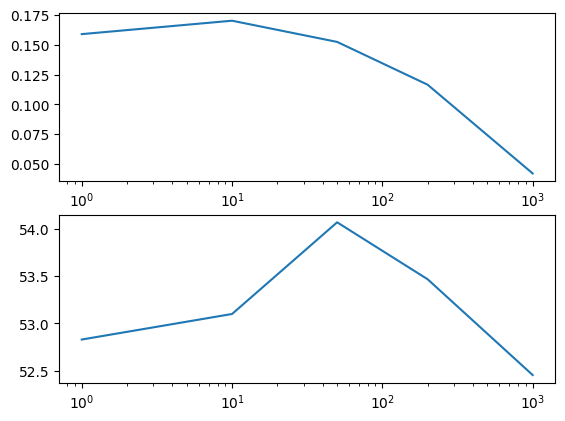

In [40]:
ndcgs, times = plot_graphs(interactions)

##### Задание 3.1. Перейдем к [ALS](http://yifanhu.net/PUB/cf.pdf). Возьмем реализацию iALS из библиотеки [implicit](https://benfred.github.io/implicit/api/models/cpu/als.html). Обучите ALS на нашем датасете, сделайте top_k рекомендации для юзеров из тестового датасета, и сравните метрики ALS с метриками, которые получились в SVD. Попробуйте перебрать гиперпараметры и найдите оптимальное число факторов, коэффициент alpha и коэффициент регуляризации.

In [41]:
!pip install implicit


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 74.8 MB/s eta 0:00:00


In [42]:
import implicit
from scipy.sparse import csr_matrix

In [43]:
def make_als_recommendations(
    interactions: Union[np.ndarray, coo_array],
    top_k: int = 100,
    n_factors: int = 100,
    alpha: float = 1.0,
    regularization: float = 0.01,
):
    interactions = csr_matrix(interactions)

    model = implicit.als.AlternatingLeastSquares(
        factors=n_factors,
        regularization=regularization,
        alpha=alpha,
        random_state=42
    )
    model.fit(interactions, show_progress=False)
    userids = np.arange(interactions.shape[0])
    recommendations = model.recommend(userids, interactions[userids], N=top_k, filter_already_liked_items=True)[0]
    return model, recommendations #shape ~ [n_users, top_k]

In [44]:
model, recs = make_als_recommendations(interactions)
assert recs.shape == (interactions.shape[0], 100)

/usr/local/lib/python3.13/dist-packages/implicit/cpu/als.py:96: RuntimeWarning: OpenBLAS is configured to use 2 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


In [45]:
metrics = pd.DataFrame()
for n_factors in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 25, 50, 100, 250, 500]:
    _, recs = make_als_recommendations(interactions, n_factors=n_factors)
    metrics = pd.concat([metrics, pd.DataFrame({'n_factors': [n_factors], 'nDCG@k': [ndcg(df_test, recs, top_k=100)]})])
metrics

,n_factors,nDCG@k
0,1,0.159681
0,2,0.163232
0,3,0.162861
0,4,0.166853
0,5,0.169262
0,6,0.170478
0,7,0.169747
0,8,0.168999
0,9,0.167190
0,10,0.166723


In [46]:
metrics = pd.DataFrame()
for alpha in [0.1, 0.3, 0.5, 0.7, 1, 2, 5, 10, 15, 20]:
    _, recs = make_als_recommendations(interactions, n_factors=6, alpha=alpha)
    metrics = pd.concat([metrics, pd.DataFrame({'alpha': [alpha], 'nDCG@k': [ndcg(df_test, recs, top_k=100)]})])
metrics

,alpha,nDCG@k
0,0.1,0.170772
0,0.3,0.174855
0,0.5,0.172884
0,0.7,0.171416
0,1.0,0.170478
0,2.0,0.165766
0,5.0,0.159144
0,10.0,0.151917
0,15.0,0.146627
0,20.0,0.141609


In [47]:
metrics = pd.DataFrame()
for regularization in [0.01, 0.1, 0.5, 1]:
    _, recs = make_als_recommendations(interactions, n_factors=6, alpha=0.3, regularization=regularization)
    metrics = pd.concat([metrics, pd.DataFrame({'regularization': [regularization], 'nDCG@k': [ndcg(df_test, recs, top_k=100)]})])
metrics

,regularization,nDCG@k
0,0.01,0.174855
0,0.10,0.174685
0,0.50,0.174515
0,1.00,0.174828


In [48]:
model, recs = make_als_recommendations(interactions, n_factors=6, alpha=0.3, regularization=0.01)
ndcg(df_test, recs, top_k=100)

np.float64(0.17485492459041113)

##### Задание 3.2. Сделайте объяснение рекомендаций для нескольких юзеров(als.explain). Воспользуйтесь файлом movies.dat чтобы перейти от индексов фильмов к их названием

In [49]:
def item_id_to_movie_name(item_id):
    if item_id not in item_le.classes_:
        return 'UNKNOWN'
    return item_le.transform([item_id])[0]

movies = pd.read_csv("ml-1m/movies.dat", sep='::', names=['item_id', 'movie_name', 'movie_tags'], engine='python', encoding='latin-1')
movies.head()

,item_id,movie_name,movie_tags
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [50]:
movies['item_id'] = movies['item_id'].apply(item_id_to_movie_name)
movies

,item_id,movie_name,movie_tags
0,0,Toy Story (1995),Animation|Children's|Comedy
1,1,Jumanji (1995),Adventure|Children's|Fantasy
2,2,Grumpier Old Men (1995),Comedy|Romance
3,3,Waiting to Exhale (1995),Comedy|Drama
4,4,Father of the Bride Part II (1995),Comedy
...,...,...,...
3878,3005,Meet the Parents (2000),Comedy
3879,3006,Requiem for a Dream (2000),Drama
3880,3007,Tigerland (2000),Drama
3881,3008,Two Family House (2000),Drama


In [51]:
user_id = 0
item_id = 1

explains = model.explain(user_id, csr_matrix(interactions[user_id]), item_id)[1]
explains

[(np.int32(2119), np.float64(0.0015185937440536704)),
 (np.int32(681), np.float64(0.0014353515459039404)),
 (np.int32(1982), np.float64(0.0012513176013161263)),
 (np.int32(1554), np.float64(0.0005886852132987926)),
 (np.int32(1541), np.float64(0.0005485816770886858)),
 (np.int32(682), np.float64(0.0003951557023638448)),
 (np.int32(2173), np.float64(0.0002990111745780352)),
 (np.int32(397), np.float64(0.0002193453641554505)),
 (np.int32(65), np.float64(0.00018502646898494815)),
 (np.int32(2467), np.float64(0.00018443365145048935))]

In [52]:
movies[movies['item_id'] == item_id]['movie_name'].item()

'Jumanji (1995)'

In [53]:
explains = [(movies[movies['item_id'] == x]['movie_name'].item(), y) for x, y in explains]
explains

[('Airplane! (1980)', np.float64(0.0015185937440536704)),
 ('Wizard of Oz, The (1939)', np.float64(0.0014353515459039404)),
 ('Star Wars: Episode I - The Phantom Menace (1999)',
  np.float64(0.0012513176013161263)),
 ('Return from Witch Mountain (1978)', np.float64(0.0005886852132987926)),
 ('Journey of Natty Gann, The (1985)', np.float64(0.0005485816770886858)),
 ('Gone with the Wind (1939)', np.float64(0.0003951557023638448)),
 ("Hard Day's Night, A (1964)", np.float64(0.0002990111745780352)),
 ('In the Army Now (1994)', np.float64(0.0002193453641554505)),
 ('Misérables, Les (1995)', np.float64(0.00018502646898494815)),
 ('Alive (1993)', np.float64(0.00018443365145048935))]

##### Задание 4. До этого мы работали с рейтингами, но как обсуждалось на лекции, implicit ALS отлично работает и с implicit фидбэком. Давайте попробуем преобразовать наш датасет(трейн и тест) следующим образом

1. Бинаризуем все рейтинги(заменим любую интеракцию пользователя на 1)
2. Заменим на 1 только рейтинги 4 и 5, а рейтинг ниже 4 заменим на 0
3. Заменим на 1 только рейтинги 4 и 5, а рейтинг ниже 4 заменим на -1
4. Заменим на 1 только рейтинги 4 и 5, а рейтинг ниже 4 заменим на -1 и добавим сглаживание по времени. То есть чем дальше была интеракция от максимальной даты трейна, тем с меньшим весом мы будем ее учитывать(например можно интеракции за последний месяц брать в исходном виде, и с каждым месяцем в прошлое умножать их на какой-нибудь коэффициент меньший 1). Таким образом более старые интеракции пользователя будут вносить меньший вклад в его интересы
5. Придумайте свой вариант(опционально)

Для каждой полученной матрицы обучите iALS и SVD и сравните их результаты между собой(преобразовывать нужно только обучающую выборку, тестовую оставляем неизменной)

In [54]:
df_train['rating']

,rating
100409,3
100411,4
100412,4
100415,1
100416,4
...,...
1000204,1
1000205,5
1000206,5
1000207,4


In [57]:
def test_1_binary(df):
    df_binary = df.copy()
    df_binary['rating'] = 1
    return df_binary

def test_2_binary(df):
    df_binary = df[df['rating'] >= 4].copy()
    df_binary['rating'] = 1
    return df_binary

def test_3_binary(df):
    df_binary = df.copy()
    df_binary['rating'] = df_binary['rating'].apply(lambda x : 1 if x >= 4 else -1)
    return df_binary

def test_4_time_weighted(df, decay=0.5):
    df_time_weighted = df.copy()
    df_time_weighted['rating'] = df_time_weighted['rating'].apply(lambda x: 1 if x >= 4 else -1)

    df_max_dt = df_time_weighted['datetime'].max()
    months_ago = (df_max_dt - df_time_weighted['datetime']).dt.days / 30.0

    df_time_weighted['rating'] = df_time_weighted['rating'] * (decay ** months_ago)
    return df_time_weighted

In [58]:
TOP_K = 100
N_USERS, N_ITEMS = interactions.shape

def build_coo(df_p):
    return coo_array(
        (df_p['rating'].values.astype(float),
         (df_p['user_id'].values, df_p['item_id'].values)),
        shape=(N_USERS, N_ITEMS)
    )

def als_recs(M, factors=6, alpha=0.3, reg=0.01):
    R = csr_matrix(M)
    R.data = np.clip(R.data, 0, None)
    m = implicit.als.AlternatingLeastSquares(
        factors=factors, regularization=reg, alpha=alpha, random_state=42
    )
    m.fit(R, show_progress=False)
    uids = np.arange(N_USERS)
    return m.recommend(uids, R[uids], N=TOP_K, filter_already_liked_items=True)[0]

rows = []
for name, fn in [('1_binary',       test_1_binary),
                 ('2_binary_4+',    test_2_binary),
                 ('3_pm1',          test_3_binary),
                 ('4_time_weighted',test_4_time_weighted)]:
    M = build_coo(fn(df_train))

    als_score = ndcg(df_test, als_recs(M), top_k=TOP_K)
    svd_score = ndcg(df_test,
                     make_svd_recommendations(M, n_singular_values=10, top_k=TOP_K),
                     top_k=TOP_K)

    rows.append({'prep': name, 'ALS': als_score, 'SVD': svd_score})
    print(f"{name:18s} | ALS: {als_score:.4f} | SVD: {svd_score:.4f}")

print(pd.DataFrame(rows))

1_binary           | ALS: 0.1650 | SVD: 0.1605
2_binary_4+        | ALS: 0.1495 | SVD: 0.1463
3_pm1              | ALS: 0.1716 | SVD: 0.1663
4_time_weighted    | ALS: 0.1690 | SVD: 0.1638
              prep       ALS       SVD
0         1_binary  0.165015  0.160522
1      2_binary_4+  0.149450  0.146321
2            3_pm1  0.171595  0.166272
3  4_time_weighted  0.168984  0.163792


##### Задание 5. iALS на numpy/torch. Давайте реализуем алгоритм iALS на нумпае или торче. Требуется реализовать алгорит, описанный в 4 части [статьи](http://yifanhu.net/PUB/cf.pdf). Обратите внимания на все оптимизации, которые они описывают в статье, чтобы сократить лишние вычисления. Hint: метрики у вашего алгоритма должны быть сравнимы с метриками ALS из библиотеки implicit

In [59]:
import numpy as np
from scipy.sparse import csr_matrix

class iALS:
    def __init__(self, n_factors: int = 100, alpha: float = 1.0, reg_coef: float = 0.01):
        self.n_factors = n_factors
        self.alpha = alpha
        self.reg_coef = reg_coef

        self.X = None  # user factors, shape (n_users, n_factors)
        self.Y = None  # item factors, shape (n_items, n_factors)
        self.user_items = None  # список индексов айтемов для каждого пользователя
        self.item_users = None  # список индексов пользователей для каждого айтема
        self.user_confidence = None  # c_{ui} для ненулевых пар пользователя
        self.item_confidence = None  # c_{ui} для ненулевых пар айтема

    def fit(self, interactions: np.ndarray, n_iterations: int = 10):
        R = csr_matrix(interactions)
        n_users, n_items = R.shape

        # Строим списки ненулевых взаимодействий
        self.user_items = [R.indices[R.indptr[i]:R.indptr[i+1]] for i in range(n_users)]
        self.item_users = [R.indices[R.indptr[j]:R.indptr[j+1]] for j in range(R.shape[1])] \
            if False else self._build_item_users(R)

        # Confidence для ненулевых пар: c_{ui} = 1 + alpha * r_{ui}
        # Для нулевых: c_{ui} = 1
        self.user_confidence = [1 + self.alpha * R.data[R.indptr[i]:R.indptr[i+1]] for i in range(n_users)]
        self.item_confidence = self._build_item_confidence(R)

        # Инициализация случайными значениями
        rng = np.random.default_rng(42)
        self.X = rng.normal(0, 0.01, (n_users, self.n_factors))
        self.Y = rng.normal(0, 0.01, (n_items, self.n_factors))

        # Чередуем пересчёт
        for iteration in range(n_iterations):
            self._update_users()
            self._update_items()

        return self

    def _build_item_users(self, R):
        item_users = [[] for _ in range(R.shape[1])]
        for u in range(R.shape[0]):
            for j, v in zip(R.indices[R.indptr[u]:R.indptr[u+1]], R.data[R.indptr[u]:R.indptr[u+1]]):
                item_users[j].append(u)
        return [np.array(lst) for lst in item_users]

    def _build_item_confidence(self, R):
        item_confidence = [[] for _ in range(R.shape[1])]
        for u in range(R.shape[0]):
            for j, v in zip(R.indices[R.indptr[u]:R.indptr[u+1]], R.data[R.indptr[u]:R.indptr[u+1]]):
                item_confidence[j].append(1 + self.alpha * v)
        return [np.array(lst) for lst in item_confidence]

    def _update_users(self):
        # Предвычисляем Y^T Y — общая для всех пользователей
        YtY = self.Y.T @ self.Y
        n_users = self.X.shape[0]
        lambda_I = self.reg_coef * np.eye(self.n_factors)

        for u in range(n_users):
            items = self.user_items[u]
            if len(items) == 0:
                continue

            Y_u = self.Y[items]
            c_u = self.user_confidence[u]

            c_minus_1 = c_u - 1

            Yt_C_minus_I_Y = (Y_u * c_minus_1[:, None]).T @ Y_u

            # Левая часть
            A = YtY + Yt_C_minus_I_Y + lambda_I

            # Правая часть
            b = (Y_u * c_u[:, None]).sum(axis=0)

            self.X[u] = np.linalg.solve(A, b)

    def _update_items(self):
        XtX = self.X.T @ self.X
        n_items = self.Y.shape[0]
        lambda_I = self.reg_coef * np.eye(self.n_factors)

        for i in range(n_items):
            users = self.item_users[i]
            if len(users) == 0:
                continue

            X_i = self.X[users]
            c_i = self.item_confidence[i]
            c_minus_1 = c_i - 1

            Xt_C_minus_I_X = (X_i * c_minus_1[:, None]).T @ X_i
            A = XtX + Xt_C_minus_I_X + lambda_I

            b = (X_i * c_i[:, None]).sum(axis=0)

            self.Y[i] = np.linalg.solve(A, b)

    def predict(self, top_k: int = 100) -> np.ndarray:
        """
        Возвращает top-k айтемов для каждого пользователя.
        Исключает айтемы, с которыми пользователь уже взаимодействовал.
        """
        scores = self.X @ self.Y.T
        n_users = scores.shape[0]

        # Исключаем уже просмотренные
        for u in range(n_users):
            items = self.user_items[u]
            if len(items) > 0:
                scores[u, items] = -np.inf

        top_k = min(top_k, scores.shape[1])
        predicts = np.argpartition(-scores, top_k, axis=1)[:, :top_k]

        row_indices = np.arange(n_users)[:, None]
        top_scores = scores[row_indices, predicts]
        order = np.argsort(-top_scores, axis=1)
        predicts = predicts[row_indices, order]

        return predicts

In [60]:
my_als = iALS(n_factors=6, alpha=0.3, reg_coef=0.01)
my_als.fit(interactions, n_iterations=10)

my_recs = my_als.predict(top_k=100)
print(my_recs.shape)  # (n_users, 100)

my_ndcg = ndcg(df_test, my_recs, top_k=100)
print(f"iALS (numpy): nDCG@100 = {my_ndcg:.4f}")

# Сравниваем с implicit
from implicit.als import AlternatingLeastSquares

model = AlternatingLeastSquares(
    factors=6,
    alpha=0.3,
    regularization=0.01,
    random_state=42
)
model.fit(csr_matrix(interactions), show_progress=False)

userids = np.arange(interactions.shape[0])
implicit_recs = model.recommend(
    userids,
    csr_matrix(interactions)[userids],
    N=100,
    filter_already_liked_items=True
)[0]

implicit_ndcg = ndcg(df_test, implicit_recs, top_k=100)
print(f"implicit ALS: nDCG@100 = {implicit_ndcg:.4f}")

(5365, 100)
iALS (numpy): nDCG@100 = 0.1690
implicit ALS: nDCG@100 = 0.1749
